# Task 23: Manual Variance Inflation Factor (VIF) Analysis

## Objective
To detect multicollinearity among numerical features by manually
calculating R-squared values through multiple linear regression and
computing VIF without built-in regression or multicollinearity functions.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [11]:
numerical_df = df.select_dtypes(include=["number"])

# Exclude target because VIF is calculated for predictor features
feature_columns = [
    col for col in numerical_df.columns
    if col != "target"
]

# Remove rows containing missing or infinite values
X_df = numerical_df[feature_columns].replace(
    [np.inf, -np.inf], np.nan
).dropna()

# Remove constant columns because their variance is zero
valid_columns = []

for col in feature_columns:
    values = X_df[col].tolist()

    if len(values) > 0 and max(values) != min(values):
        valid_columns.append(col)

X_df = X_df[valid_columns]

print("Features used:", list(X_df.columns))
print("Rows used:", len(X_df))

Features used: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Rows used: 1025


In [12]:
def manual_mean(values):
    return sum(values) / len(values)


def manual_r_squared(actual, predicted):
    mean_actual = manual_mean(actual)

    ss_total = sum(
        (value - mean_actual) ** 2 for value in actual
    )

    ss_residual = sum(
        (actual[i] - predicted[i]) ** 2
        for i in range(len(actual))
    )

    if ss_total == 0:
        return 0

    return 1 - ss_residual / ss_total

In [13]:
def manual_linear_regression_r2(X, y):
    n = len(y)

    # Add intercept column
    X_with_intercept = np.column_stack((
        np.ones(n),
        X
    ))

    # Normal equation with small numerical stabilization
    xtx = X_with_intercept.T @ X_with_intercept
    xty = X_with_intercept.T @ y

    ridge = 1e-8
    xtx_stable = xtx.copy()

    for i in range(1, xtx_stable.shape[0]):
        xtx_stable[i, i] += ridge

    coefficients = np.linalg.pinv(xtx_stable) @ xty

    predictions = X_with_intercept @ coefficients

    return manual_r_squared(
        y.tolist(),
        predictions.tolist()
    )

In [14]:
vif_results = []

X = X_df.to_numpy(dtype=float)
columns = list(X_df.columns)

for i, feature in enumerate(columns):
    y = X[:, i]

    # All other features become predictors
    other_indices = [
        j for j in range(len(columns)) if j != i
    ]

    if len(other_indices) == 0:
        r_squared = 0
    else:
        X_other = X[:, other_indices]
        r_squared = manual_linear_regression_r2(
            X_other, y
        )

    # Protect against tiny floating-point errors
    r_squared = max(0, min(r_squared, 1))

    if r_squared >= 1 - 1e-10:
        vif = float("inf")
    else:
        vif = 1 / (1 - r_squared)

    vif_results.append({
        "Feature": feature,
        "R-squared": r_squared,
        "VIF": vif
    })

vif_df = pd.DataFrame(vif_results)
vif_df = vif_df.sort_values(
    by="VIF", ascending=False
).reset_index(drop=True)

print(vif_df.to_string(index=False))

 Feature  R-squared      VIF
 oldpeak   0.414710 1.708555
   slope   0.391391 1.643092
 thalach   0.380875 1.615182
     age   0.300147 1.428872
   exang   0.295302 1.419047
      cp   0.226770 1.293277
      ca   0.164623 1.197065
trestbps   0.143755 1.167890
     sex   0.134909 1.155948
    chol   0.127435 1.146047
    thal   0.121018 1.137680
     fbs   0.082622 1.090063
 restecg   0.060540 1.064442


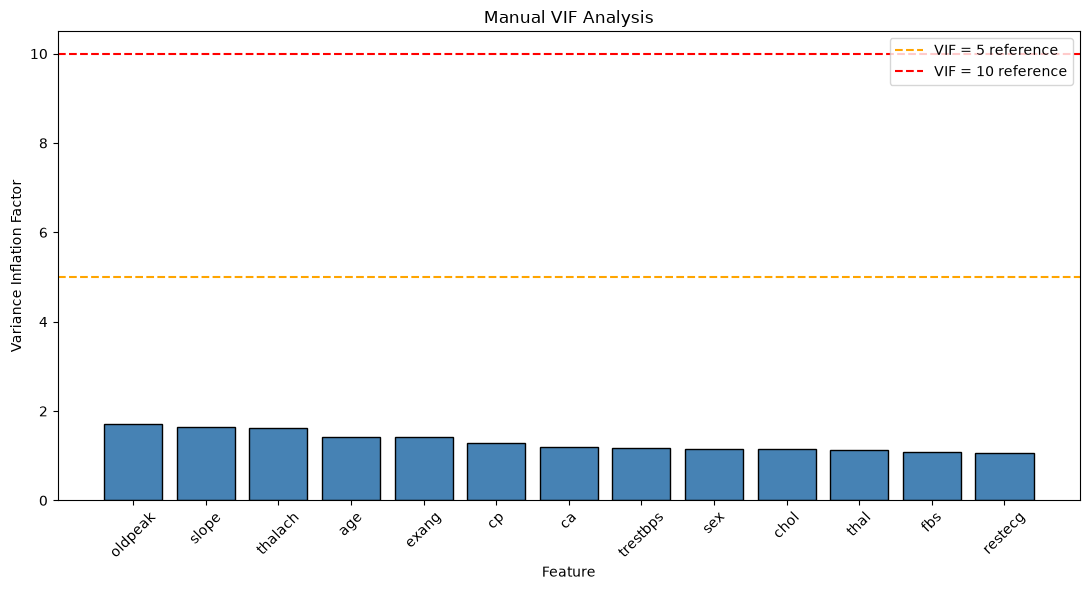

In [15]:
plot_vif = vif_df.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["VIF"])

plt.figure(figsize=(11, 6))

plt.bar(
    plot_vif["Feature"],
    plot_vif["VIF"],
    color="steelblue",
    edgecolor="black"
)

plt.axhline(
    5,
    color="orange",
    linestyle="--",
    label="VIF = 5 reference"
)

plt.axhline(
    10,
    color="red",
    linestyle="--",
    label="VIF = 10 reference"
)

plt.xlabel("Feature")
plt.ylabel("Variance Inflation Factor")
plt.title("Manual VIF Analysis")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
print("VIF Interpretation:\n")

for _, row in vif_df.iterrows():
    feature = row["Feature"]
    vif = row["VIF"]

    if not np.isfinite(vif):
        interpretation = "Potential perfect multicollinearity"
    elif vif >= 10:
        interpretation = "High multicollinearity"
    elif vif >= 5:
        interpretation = "Moderate multicollinearity"
    else:
        interpretation = "Relatively low multicollinearity"

    print(f"{feature}: VIF = {vif:.3f} — {interpretation}")

VIF Interpretation:

oldpeak: VIF = 1.709 — Relatively low multicollinearity
slope: VIF = 1.643 — Relatively low multicollinearity
thalach: VIF = 1.615 — Relatively low multicollinearity
age: VIF = 1.429 — Relatively low multicollinearity
exang: VIF = 1.419 — Relatively low multicollinearity
cp: VIF = 1.293 — Relatively low multicollinearity
ca: VIF = 1.197 — Relatively low multicollinearity
trestbps: VIF = 1.168 — Relatively low multicollinearity
sex: VIF = 1.156 — Relatively low multicollinearity
chol: VIF = 1.146 — Relatively low multicollinearity
thal: VIF = 1.138 — Relatively low multicollinearity
fbs: VIF = 1.090 — Relatively low multicollinearity
restecg: VIF = 1.064 — Relatively low multicollinearity


## Conclusion

In this task, Variance Inflation Factor (VIF) was calculated manually
to investigate multicollinearity among numerical predictor features.
Each feature was regressed against the remaining features, and its
R-squared value was used to compute VIF.

Higher VIF values indicate that a feature can be explained more strongly
by the other predictors. VIF thresholds such as 5 and 10 are guidelines,
not absolute rules. Results should be interpreted in the context of
the dataset and modeling objective.